# Predicting Next-Day S&P 500 Direction Using Machine Learning

**Team members:** Amaaz Lakhani and Waseem Kazzali 

## 1. Objective

The goal is to predict whether the S&P 500 closing price will increase on the next trading day. Features for day $t$ use only information available through the close of day $t$, and the target indicates whether the close on day $t+1$ is higher.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "sp500_index.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
for directory in [PROCESSED_DIR, FIGURE_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


## 2. Load the dataset

The dataset was downloaded from Yahoo Finance using ticker `^GSPC` and stored with the project label `SPX`. It contains daily open, high, low, close, and volume observations.

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f"Rows: {len(raw):,}")
print(f"Columns: {list(raw.columns)}")
display(raw.head())

Rows: 6,741
Columns: ['date', 'open', 'high', 'low', 'close', 'volume', 'symbol']


,date,open,high,low,close,volume,symbol
0,2000-01-03,1469.25,1478.00,1438.36,1455.22,931800000,SPX
1,2000-01-04,1455.22,1455.22,1397.43,1399.42,1009000000,SPX
2,2000-01-05,1399.42,1413.27,1377.68,1402.11,1085500000,SPX
3,2000-01-06,1402.11,1411.90,1392.10,1403.45,1092300000,SPX
4,2000-01-07,1403.45,1441.47,1400.73,1441.47,1225200000,SPX


## 3. Data cleaning and validation

Checks identify missing values, duplicate dates, invalid prices or volume, and inconsistent OHLC relationships. One zero-volume value is treated as unavailable and interpolated, while large market movements are retained because they may be genuine observations.

In [3]:
required_columns = ["date", "open", "high", "low", "close", "volume", "symbol"]
price_columns = ["open", "high", "low", "close"]
numeric_columns = price_columns + ["volume"]

missing_columns = sorted(set(required_columns) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

clean = raw[required_columns].copy()
clean["date"] = pd.to_datetime(clean["date"], errors="coerce")
for column in numeric_columns:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")

missing_by_column = clean.isna().sum()
exact_duplicates = int(clean.duplicated().sum())
duplicate_dates = int(clean.duplicated(subset=["date"]).sum())
invalid_prices = int((clean[price_columns] <= 0).any(axis=1).sum())
negative_volume = int((clean["volume"] < 0).sum())
invalid_ohlc = int(((clean["high"] < clean[["open", "close", "low"]].max(axis=1)) |
                    (clean["low"] > clean[["open", "close", "high"]].min(axis=1))).sum())
zero_volume = int((clean["volume"] == 0).sum())

quality_summary = pd.DataFrame({
    "check": ["Rows", "Missing values", "Exact duplicates", "Duplicate dates",
              "Invalid prices", "Negative volume", "Invalid OHLC rows", "Zero-volume rows"],
    "count": [len(clean), int(missing_by_column.sum()), exact_duplicates, duplicate_dates,
              invalid_prices, negative_volume, invalid_ohlc, zero_volume],
})
display(quality_summary)

,check,count
0,Rows,6741
1,Missing values,0
2,Exact duplicates,0
3,Duplicate dates,0
4,Invalid prices,0
5,Negative volume,0
6,Invalid OHLC rows,0
7,Zero-volume rows,1


In [4]:
# Apply the documented cleaning rules.
clean = clean.dropna(subset=required_columns).drop_duplicates()
clean = clean.drop_duplicates(subset=["date"], keep="last")
valid_market_row = (
    (clean[price_columns] > 0).all(axis=1)
    & (clean["volume"] >= 0)
    & (clean["high"] >= clean[["open", "close", "low"]].max(axis=1))
    & (clean["low"] <= clean[["open", "close", "high"]].min(axis=1))
)
clean = clean.loc[valid_market_row].sort_values("date").reset_index(drop=True)

# Zero index volume is treated as unavailable and interpolated from adjacent days.
clean.loc[clean["volume"] == 0, "volume"] = np.nan
clean["volume"] = clean["volume"].interpolate(method="linear").round().astype("int64")
clean["symbol"] = "SPX"
clean[price_columns] = clean[price_columns].round(2)
clean["daily_return"] = clean["close"].pct_change(fill_method=None)

large_moves = clean.loc[clean["daily_return"].abs() >= 0.05,
                        ["date", "close", "daily_return"]].copy()
print(f"Clean rows retained: {len(clean):,}")
print(f"Date range: {clean['date'].min().date()} to {clean['date'].max().date()}")
print(f"Daily moves of at least 5% retained: {len(large_moves)}")

Clean rows retained: 6,741
Date range: 2000-01-03 to 2026-10-21
Daily moves of at least 5% retained: 39


In [5]:
clean_output = clean.drop(columns="daily_return")
clean_output.to_csv(
    PROCESSED_DIR / "sp500_index_clean.csv",
    index=False,
    date_format="%Y-%m-%d",
    float_format="%.2f",
)

## 4. Feature engineering and target construction

All predictors for a row use information available by the end of that row's trading day. The following day's close is used only to construct the target.

In [6]:
def calculate_rsi(close, window=14):
    change = close.diff()
    gains = change.clip(lower=0)
    losses = -change.clip(upper=0)
    average_gain = gains.rolling(window, min_periods=window).mean()
    average_loss = losses.rolling(window, min_periods=window).mean()
    relative_strength = average_gain / average_loss.replace(0, np.nan)
    rsi = 100 - 100 / (1 + relative_strength)
    rsi = rsi.mask((average_loss == 0) & (average_gain > 0), 100.0)
    rsi = rsi.mask((average_loss == 0) & (average_gain == 0), 50.0)
    return rsi

model_data = clean.copy()
daily_return = model_data["close"].pct_change(fill_method=None)
model_data["return_1d"] = daily_return
model_data["return_5d"] = model_data["close"].pct_change(5, fill_method=None)
model_data["return_20d"] = model_data["close"].pct_change(20, fill_method=None)
model_data["ma_ratio_5"] = model_data["close"] / model_data["close"].rolling(5).mean() - 1
model_data["ma_ratio_20"] = model_data["close"] / model_data["close"].rolling(20).mean() - 1
model_data["volatility_5"] = daily_return.rolling(5).std()
model_data["volatility_20"] = daily_return.rolling(20).std()
model_data["rsi_14"] = calculate_rsi(model_data["close"], 14)
model_data["daily_range"] = (model_data["high"] - model_data["low"]) / model_data["close"]
model_data["intraday_return"] = (model_data["close"] - model_data["open"]) / model_data["open"]
model_data["volume_change_1d"] = model_data["volume"].pct_change(fill_method=None)
model_data["direction_1d"] = (daily_return > 0).astype(int)

next_day_return = model_data["close"].shift(-1) / model_data["close"] - 1
model_data["target"] = np.where(
    next_day_return.isna(), np.nan, (next_day_return > 0).astype(int)
)

feature_columns = [
    "return_1d", "return_5d", "return_20d", "ma_ratio_5", "ma_ratio_20",
    "volatility_5", "volatility_20", "rsi_14", "daily_range",
    "intraday_return", "volume_change_1d", "direction_1d",
]
model_data = model_data[["date", *feature_columns, "target"]]
model_data = model_data.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
model_data["target"] = model_data["target"].astype(int)
print(f"Modeling rows: {len(model_data):,}")
print(f"Feature count: {len(feature_columns)}")

Modeling rows: 6,720
Feature count: 12


## 5. Chronological train, validation, and test split

Random splitting is not used because it could allow future market observations to influence earlier predictions. Scaling will be fitted on training data only during modeling.

In [7]:
train_end = int(len(model_data) * 0.70)
validation_end = int(len(model_data) * 0.85)
model_data["split"] = np.select(
    [model_data.index < train_end, model_data.index < validation_end],
    ["train", "validation"],
    default="test",
)

split_summary = model_data.groupby("split", sort=False).agg(
    rows=("date", "size"),
    start_date=("date", "min"),
    end_date=("date", "max"),
    up_day_percentage=("target", lambda values: 100 * values.mean()),
)
display(split_summary.round(2))

model_data.to_csv(
    PROCESSED_DIR / "sp500_modeling_data.csv", index=False, date_format="%Y-%m-%d"
)

/var/folders/qy/fm24xxts2zvfydy94l0r01gw0000gn/T/ipykernel_15337/2242478087.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(split_summary.round(2))


,rows,start_date,end_date,up_day_percentage
split,,,,
train,4704,2000-02-01,2018-10-10,53.36
validation,1008,2018-10-11,2022-10-12,54.17
test,1008,2022-10-13,2026-10-20,54.76


## 6. Exploratory data analysis

The analysis examines price and return distributions, target-class balance, feature correlations, descriptive statistics, and unusually large daily market movements.

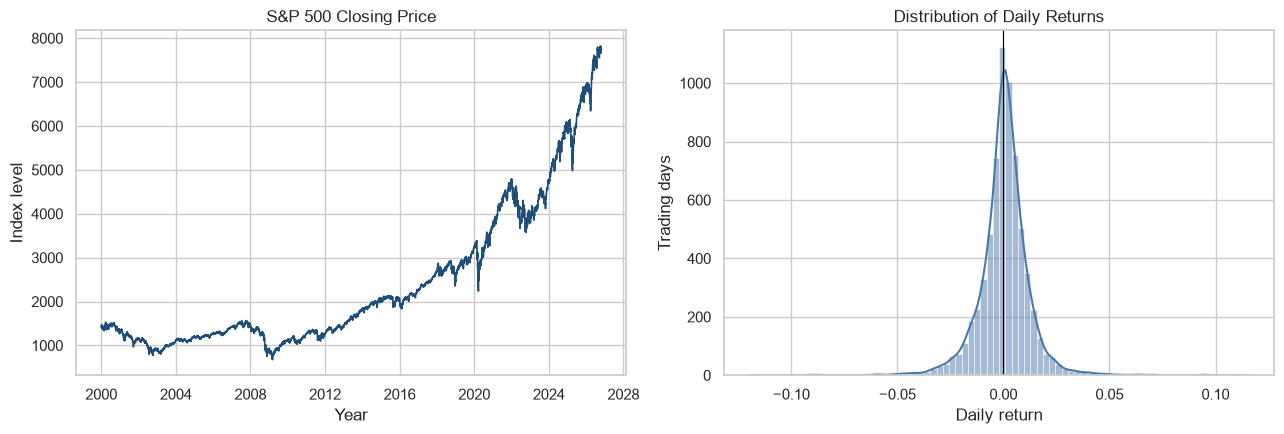

In [8]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(clean["date"], clean["close"], color="#1f4e79", linewidth=1.2)
axes[0].set(title="S&P 500 Closing Price", xlabel="Year", ylabel="Index level")

sns.histplot(clean["daily_return"].dropna(), bins=80, kde=True, ax=axes[1], color="#4c78a8")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(title="Distribution of Daily Returns", xlabel="Daily return", ylabel="Trading days")

figure.tight_layout()
figure.savefig(FIGURE_DIR / "price_and_return_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

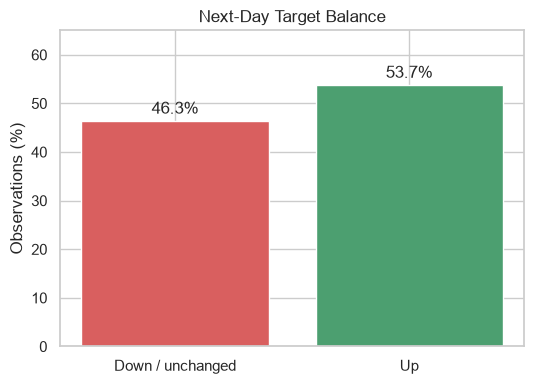

In [9]:
target_counts = model_data["target"].value_counts().sort_index()
target_percentages = 100 * target_counts / target_counts.sum()

figure, axis = plt.subplots(figsize=(5.5, 4))
bars = axis.bar(["Down / unchanged", "Up"], target_percentages, color=["#d95f5f", "#4c9f70"])
axis.set(title="Next-Day Target Balance", ylabel="Observations (%)", ylim=(0, 65))
axis.bar_label(bars, labels=[f"{value:.1f}%" for value in target_percentages], padding=3)
figure.tight_layout()
figure.savefig(FIGURE_DIR / "target_balance.png", dpi=300, bbox_inches="tight")
plt.show()

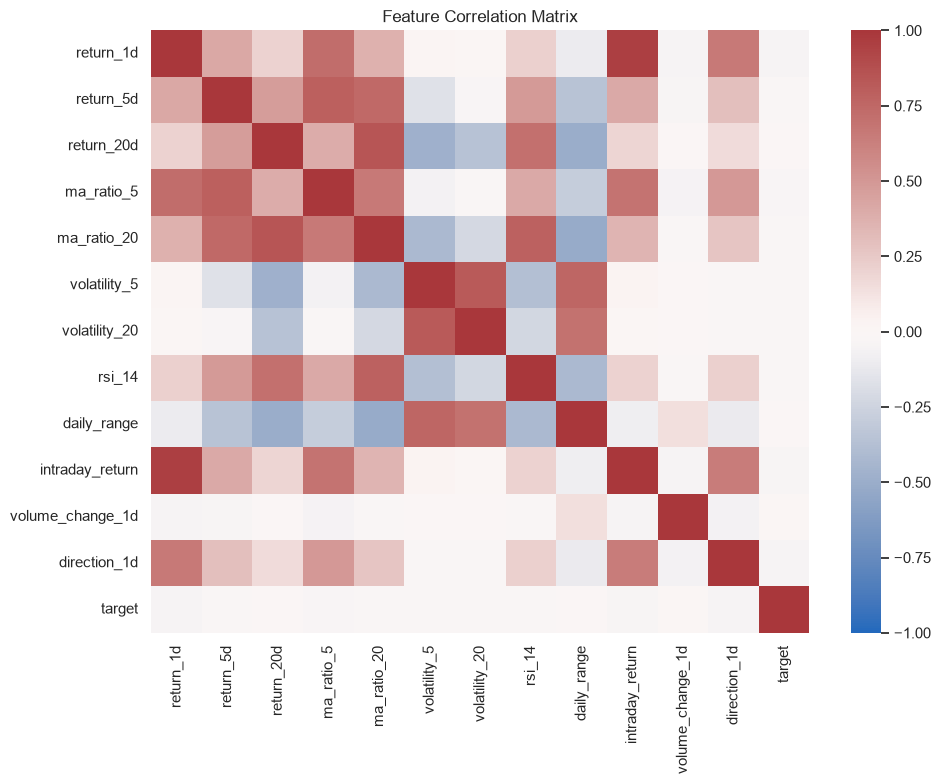

,correlation_with_target
direction_1d,-0.052161
return_1d,-0.048456
intraday_return,-0.045336
ma_ratio_5,-0.034806
return_5d,-0.029418
ma_ratio_20,-0.024415
volatility_5,-0.017455
rsi_14,-0.016772
volatility_20,-0.016491
return_20d,-0.010210


In [10]:
correlations = model_data[feature_columns + ["target"]].corr()
figure, axis = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, cmap="vlag", center=0, vmin=-1, vmax=1, ax=axis)
axis.set_title("Feature Correlation Matrix")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "feature_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

target_correlations = correlations["target"].drop("target").sort_values(key=abs, ascending=False)
display(target_correlations.to_frame("correlation_with_target"))

In [11]:
display(clean[["open", "high", "low", "close", "volume", "daily_return"]].describe().T)
display(large_moves.sort_values("daily_return").head(10))
display(large_moves.sort_values("daily_return", ascending=False).head(10))

,count,mean,std,min,25%,50%,75%,max
open,6741.0,2.418745e+03,1.668724e+03,6.792800e+02,1.217070e+03,1.625950e+03,3.046900e+03,7.813040e+03
high,6741.0,2.432303e+03,1.676163e+03,6.952700e+02,1.224760e+03,1.633700e+03,3.079760e+03,7.844520e+03
low,6741.0,2.404183e+03,1.660833e+03,6.667900e+02,1.210950e+03,1.616640e+03,3.023400e+03,7.805960e+03
close,6741.0,2.419118e+03,1.669061e+03,6.765300e+02,1.217590e+03,1.626670e+03,3.046770e+03,7.818930e+03
volume,6741.0,3.478934e+09,1.535435e+09,3.560700e+08,2.387630e+09,3.568710e+09,4.348280e+09,1.145623e+10
daily_return,6740.0,3.215882e-04,1.209648e-02,-1.198405e-01,-4.704049e-03,6.312516e-04,5.893735e-03,1.158004e-01


,date,close,daily_return
5081,2020-03-16,2386.13,-0.119841
5079,2020-03-12,2480.64,-0.095113
2209,2008-10-15,907.84,-0.090350
2241,2008-12-01,816.21,-0.089295
2197,2008-09-29,1106.42,-0.088068
2205,2008-10-09,909.92,-0.076167
5076,2020-03-09,2746.56,-0.075970
2235,2008-11-20,752.44,-0.067123
2917,2011-08-08,1119.46,-0.066634
2234,2008-11-19,806.58,-0.061156


,date,close,daily_return
2207,2008-10-13,1003.35,0.115800
2218,2008-10-28,940.51,0.107890
6355,2025-04-09,5456.90,0.095154
5087,2020-03-24,2447.33,0.093828
5080,2020-03-13,2711.02,0.092871
2317,2009-03-23,822.92,0.070758
5096,2020-04-06,2663.68,0.070331
2230,2008-11-13,911.29,0.069213
2237,2008-11-24,851.81,0.064723
2308,2009-03-10,719.60,0.063663


## 7. Initial experiments

Two initial approaches are evaluated on the validation period. The majority-class baseline predicts the most frequent training class and assigns a constant up probability equal to the training set's up-day proportion. Logistic Regression is trained with stochastic gradient descent so that training and validation log loss can be recorded after each epoch. The test period remains untouched.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix,
    f1_score, log_loss, precision_score, recall_score, roc_auc_score,
)
from sklearn.preprocessing import StandardScaler

train_data = model_data.loc[model_data["split"] == "train"].copy()
validation_data = model_data.loc[model_data["split"] == "validation"].copy()

X_train = train_data[feature_columns]
y_train = train_data["target"]
X_validation = validation_data[feature_columns]
y_validation = validation_data["target"]

# Fit scaling parameters on the training period only.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_validation_scaled = scaler.transform(X_validation)

baseline_model = DummyClassifier(strategy="prior")
baseline_model.fit(X_train_scaled, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'prior'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.47,0.53]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,12
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [13]:
epochs = 100
training_loss = []
validation_loss = []

logistic_model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=0.001,
    learning_rate="constant",
    eta0=0.0001,
    random_state=RANDOM_STATE,
)

for epoch in range(epochs):
    logistic_model.partial_fit(X_train_scaled, y_train, classes=np.array([0, 1]))
    training_loss.append(log_loss(y_train, logistic_model.predict_proba(X_train_scaled)))
    validation_loss.append(log_loss(y_validation, logistic_model.predict_proba(X_validation_scaled)))

best_epoch = int(np.argmin(validation_loss)) + 1
print(f"Lowest validation loss occurred at epoch {best_epoch}.")

# Retrain through the selected epoch so later predictions use that checkpoint.
logistic_model = SGDClassifier(
    loss="log_loss", penalty="l2", alpha=0.001,
    learning_rate="constant", eta0=0.0001, random_state=RANDOM_STATE,
)
for epoch in range(best_epoch):
    logistic_model.partial_fit(X_train_scaled, y_train, classes=np.array([0, 1]))

Lowest validation loss occurred at epoch 16.


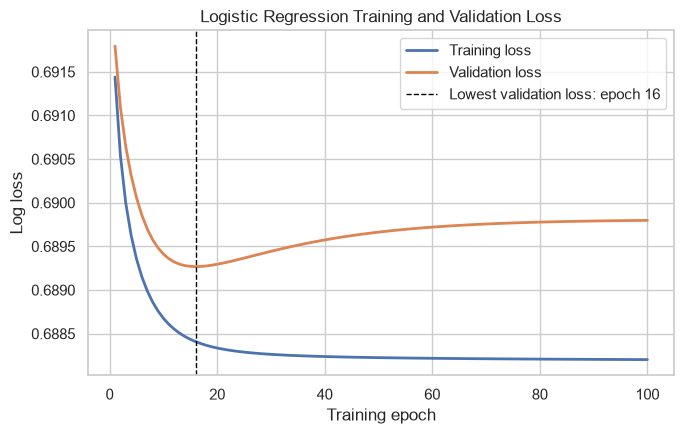

In [14]:
figure, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(range(1, epochs + 1), training_loss, label="Training loss", linewidth=2)
axis.plot(range(1, epochs + 1), validation_loss, label="Validation loss", linewidth=2)
axis.axvline(best_epoch, color="black", linestyle="--", linewidth=1,
             label=f"Lowest validation loss: epoch {best_epoch}")
axis.set(title="Logistic Regression Training and Validation Loss",
         xlabel="Training epoch", ylabel="Log loss")
axis.legend()
figure.tight_layout()
figure.savefig(FIGURE_DIR / "logistic_loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
def evaluate_model(name, model, X, y):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Precision": precision_score(y, predictions, zero_division=0),
        "Recall": recall_score(y, predictions, zero_division=0),
        "F1": f1_score(y, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y, probabilities),
        "Log Loss": log_loss(y, model.predict_proba(X)),
    }

validation_results = pd.DataFrame([
    evaluate_model("Majority Baseline", baseline_model, X_validation_scaled, y_validation),
    evaluate_model("Logistic Regression", logistic_model, X_validation_scaled, y_validation),
]).set_index("Model")
display(validation_results.round(4))
validation_results.to_csv(RESULTS_DIR / "initial_model_results.csv")

coefficient_table = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": logistic_model.coef_[0],
})
coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
display(coefficient_table.sort_values("absolute_coefficient", ascending=False).drop(columns="absolute_coefficient"))

,Accuracy,Precision,Recall,F1,ROC-AUC,Log Loss
Model,,,,,,
Majority Baseline,0.5417,0.5417,1.0000,0.7027,0.5000,0.6898
Logistic Regression,0.5278,0.5464,0.7546,0.6338,0.5183,0.6893


,feature,coefficient
11,direction_1d,-0.075868
6,volatility_20,-0.026402
0,return_1d,-0.023516
9,intraday_return,-0.021459
4,ma_ratio_20,-0.019268
5,volatility_5,-0.016036
7,rsi_14,-0.015608
1,return_5d,-0.011518
8,daily_range,-0.006604
10,volume_change_1d,0.005454


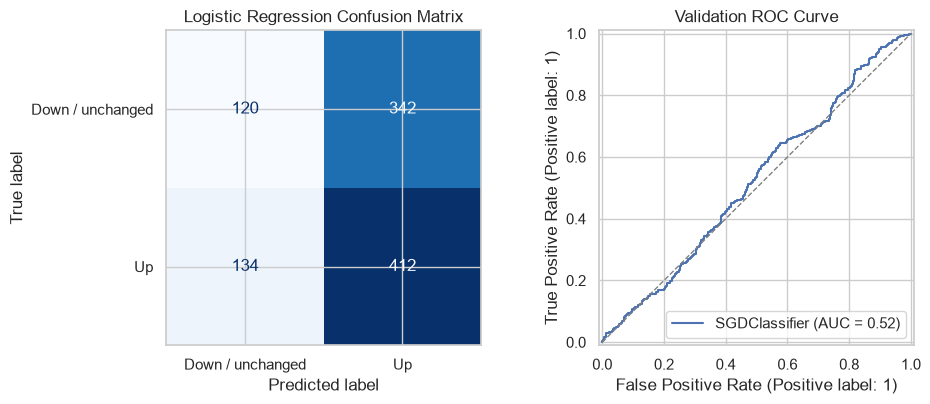

In [16]:
logistic_predictions = logistic_model.predict(X_validation_scaled)
figure, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_validation, logistic_predictions),
    display_labels=["Down / unchanged", "Up"],
).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Logistic Regression Confusion Matrix")
RocCurveDisplay.from_estimator(logistic_model, X_validation_scaled, y_validation, ax=axes[1])
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Validation ROC Curve")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "logistic_validation_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Initial experiment interpretation

On the validation period, the Logistic Regression model produced slightly lower log loss and an ROC-AUC slightly above 0.50, but its accuracy remained below the majority-class baseline. Validation loss reached its minimum at epoch 16 and then increased slightly while training loss continued to decrease, which suggests the beginning of overfitting. Overall, these preliminary results suggest that the engineered technical features contain limited linear information about next-day direction. The result is consistent with the difficulty of short-horizon market prediction and motivates testing nonlinear models and additional features in the final project. The test period was not used for model selection or for these reported intermediate results.